# CNN para classificação acústica de mosquitos

Luiz Eduardo do Nascimento Ciarallo — IFSC.

CNN realmente treinada em 11/10/2026. Avaliação **retrospectiva**, sem validação de presença ou de campo. Este notebook lê e verifica os resultados congelados; não inicia um treinamento ao abrir.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'results/ifsc_cnn_2026_10_11').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'results/ifsc_cnn_2026_10_11'
assert OUT.exists(), 'Abra na raiz do repo ou do pacote de entrega.'
protocol = json.loads((OUT/'protocol.json').read_text())
protocol

{'seed': 20261011,
 'architecture': '4 Conv2D+BN+ReLU+AvgPool; dense128; softmax20',
 'parameters': 130900,
 'device': 'cuda',
 'sample_rate': 16000,
 'samples': 15872,
 'seconds': 0.992,
 'fft': 2048,
 'hop': 256,
 'input_shape': [2, 64, 55],
 'frequency_range_hz': [80, 4000],
 'input': 'log-mel e contraste; 128 bandas agrupadas em 64; normalização por janela',
 'splits': {'train': {'windows': 9873, 'recordings': 233, 'classes': 20},
  'validation': {'windows': 2735, 'recordings': 63, 'classes': 19},
  'calibration': {'windows': 3424, 'recordings': 83, 'classes': 20},
  'test': {'windows': 7845, 'recordings': 190, 'classes': 20}},
 'epochs_max': 30,
 'patience': 6,
 'batch': 128,
 'optimizer': 'AdamW, lr=0.001, weight_decay=0.01',
 'selection': 'menor entropia cruzada de validação, equilibrada por espécie e gravação',
 'class_recording_balancing': 'amostragem inversa de janelas/gravação e gravações/espécie',
 'calibration': 'reservada, não usada: sem limiar ou rejeição neste experimen

## Arquitetura e partições
Entrada espectral com dois canais; quatro convoluções; camada de 128 unidades; saída de vinte espécies. Treino ajusta os pesos; validação escolhe a época. A calibração histórica fica reservada e não é usada.

In [2]:
frame = pd.read_csv(OUT/'partitions.csv')
assert frame.groupby('group').split.nunique().max() == 1
assert frame.groupby('path').split.nunique().max() == 1
assert frame.groupby('content_sha256').split.nunique().max() == 1
frame.groupby('split').agg(gravações=('group','nunique'), janelas=('group','size'), espécies=('label','nunique'))

,gravações,janelas,espécies
split,,,
calibration,83,3424,20
test,190,7845,20
train,233,9873,20
validation,63,2735,19


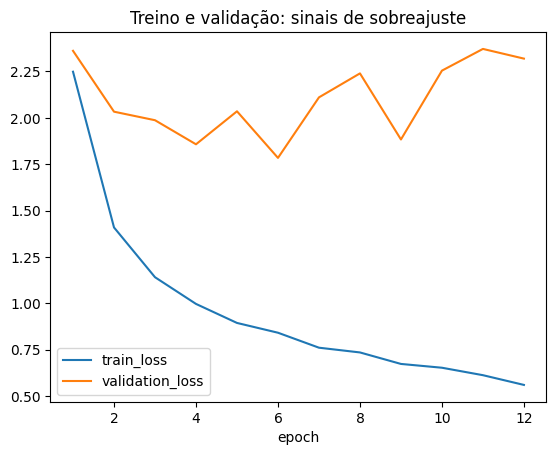

In [3]:
history = pd.read_json(OUT/'history.json')
history.plot(x='epoch', y=['train_loss','validation_loss'], title='Treino e validação: sinais de sobreajuste');

In [4]:
metrics = pd.read_csv(OUT/'metrics.csv')
metrics[['model','recordings','correct_recordings','recording_accuracy','recording_balanced_accuracy','recording_macro_f1']]

,model,recordings,correct_recordings,recording_accuracy,recording_balanced_accuracy,recording_macro_f1
0,cnn,190,105,0.552632,0.664339,0.624874
1,linear,190,136,0.715789,0.772245,0.745089


## Transferência retrospectiva
Os dezessete arquivos externos já foram examinados no projeto. Não entraram no treinamento desta CNN. Não são uma nova coleta cega; a independência de indivíduos é desconhecida. Não há ausência/ruído para medir falsos alarmes.

In [5]:
json.loads((OUT/'transfer_metrics.json').read_text())

{'recordings': 17,
 'correct': 0,
 'accuracy': 0.0,
 'classes': 5,
 'independent_new_acquisition': False,
 'historical_audio_used_in_previous_research': True,
 'model_frozen_unchanged': True,
 'checkpoint_sha256': '5957323a320dac2cacee88eba3e8000db48ac23ae0a8d391add10686cad7569a',
 'absence_noise_not_tested': True,
 'biological_independence_unknown': True}

In [6]:
freeze = json.loads((OUT/'freeze.json').read_text())
assert hashlib.sha256((OUT/'cnn.pt').read_bytes()).hexdigest() == freeze['cnn_sha256']
pred = pd.read_csv(OUT/'cnn_recordings.csv')
assert len(pred) == int(metrics.loc[metrics.model.eq('cnn'),'recordings'].iloc[0])
assert int(pred.truth.eq(pred.prediction).sum()) == int(metrics.loc[metrics.model.eq('cnn'),'correct_recordings'].iloc[0])
print('Pesos e contagens conferidos. Não equivale a validação de campo.')

Pesos e contagens conferidos. Não equivale a validação de campo.


## Redes revistas após a primeira rodada
CNN com posições de frequência preservadas e MLP profunda. As mesmas partições foram mantidas. A escolha entre as redes e as épocas usa a validação por gravação; o teste e o desafio externo são retrospectivos.

In [7]:
REV = ROOT/'results/ifsc_melhorias_2026_10_11'
selection = json.loads((REV/'selection.json').read_text())
selection

{'selected_model': 'deep_mlp',
 'criterion': 'menor entropia cruzada por gravação na validação, equilibrada por espécie',
 'candidates': [{'model': 'cnn_frequency',
   'best_epoch': 7,
   'epochs_run': 15,
   'validation_recording_loss': 1.188796783290934,
   'seconds': 17.039159297943115,
   'parameters': 224036,
   'checkpoint_sha256': 'd3445c5c4120cb04798d6e754192ace12500aa045e5b2fa6e9cc8bd238d5782b'},
  {'model': 'deep_mlp',
   'best_epoch': 32,
   'epochs_run': 40,
   'validation_recording_loss': 1.0502876169195299,
   'seconds': 3.4868738651275635,
   'parameters': 109140,
   'checkpoint_sha256': '53307ae6b2e92ba8fe04a01170c33644f6f9af5547108bc01f3641833c2d360f'}]}

In [8]:
revised = pd.read_csv(REV/'metrics.csv')
comparison = pd.concat([metrics,revised],ignore_index=True)
comparison[['model','correct_recordings','recording_accuracy','recording_balanced_accuracy','recording_macro_f1']]

,model,correct_recordings,recording_accuracy,recording_balanced_accuracy,recording_macro_f1
0,cnn,105,0.552632,0.664339,0.624874
1,linear,136,0.715789,0.772245,0.745089
2,cnn_frequency,132,0.694737,0.758164,0.714568
3,deep_mlp,132,0.694737,0.774443,0.770619


In [9]:
pd.read_csv(REV/'external_metrics.csv')[['model','correct_recordings','recordings','recording_accuracy']]

,model,correct_recordings,recordings,recording_accuracy
0,cnn_frequency_external,3,17,0.176471
1,deep_mlp_external,3,17,0.176471


In [10]:
rev_freeze = json.loads((REV/'freeze.json').read_text())
for name,expected in rev_freeze['model_sha256'].items():
    assert hashlib.sha256((REV/f'{name}.pt').read_bytes()).hexdigest() == expected
    pred = pd.read_csv(REV/f'{name}_recordings.csv')
    row = revised.loc[revised.model.eq(name)].iloc[0]
    assert len(pred) == row.recordings
    assert pred.truth.eq(pred.prediction).sum() == row.correct_recordings
assert hashlib.sha256((REV/'mlp_scaler.joblib').read_bytes()).hexdigest() == rev_freeze['scaler_sha256']
print('Redes revistas, scaler e métricas conferidos.')

Redes revistas, scaler e métricas conferidos.


Inferência do modelo escolhido pela validação:
```bash
.venv/bin/python trabalho_ifsc/inferir_melhorias.py arquivo.wav
```
A rede sempre escolhe uma espécie; a entrada não foi validada como presença de mosquito.

## Executar o programa

Inferência com pesos prontos, na raiz:
```bash
.venv/bin/python trabalho_ifsc/experimento_cnn.py --audio arquivo.wav
```

Nova rodada de treino com dados/caches já preparados no repo:
```bash
.venv/bin/python trabalho_ifsc/experimento_cnn.py --output results/ifsc_nova_rodada
```
O programa recusa sobrescrever resultados existentes. Não use a classe escolhida como prova de presença: o modelo sempre escolhe uma espécie.